['date', 'store_id', 'item_id', 'sales', 'price', 'promo', 'weekday', 'month']
         date store_id item_id  sales  price  promo  weekday  month
0  2019-01-01  store_1  item_1     41  21.30      0        1      1
1  2019-01-02  store_1  item_1     53  21.30      0        2      1
2  2019-01-03  store_1  item_1     39  21.30      0        3      1
3  2019-01-04  store_1  item_1     35  21.30      0        4      1
4  2019-01-05  store_1  item_1     51  17.04      1        5      1
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4565000 entries, 0 to 4564999
Data columns (total 8 columns):
 #   Column    Dtype  
---  ------    -----  
 0   date      object 
 1   store_id  object 
 2   item_id   object 
 3   sales     int64  
 4   price     float64
 5   promo     int64  
 6   weekday   int64  
 7   month     int64  
dtypes: float64(1), int64(4), object(3)
memory usage: 278.6+ MB
None
date        0
store_id    0
item_id     0
sales       0
price       0
promo       0
weekday     0
mont

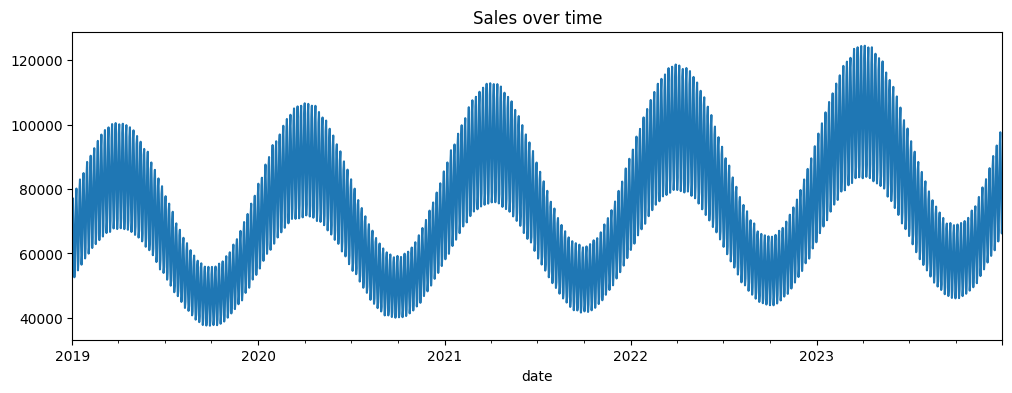

Naive: MAE=17471.66, RMSE=22011.18
Holt-Winters: MAE=44214.48, RMSE=55218.51


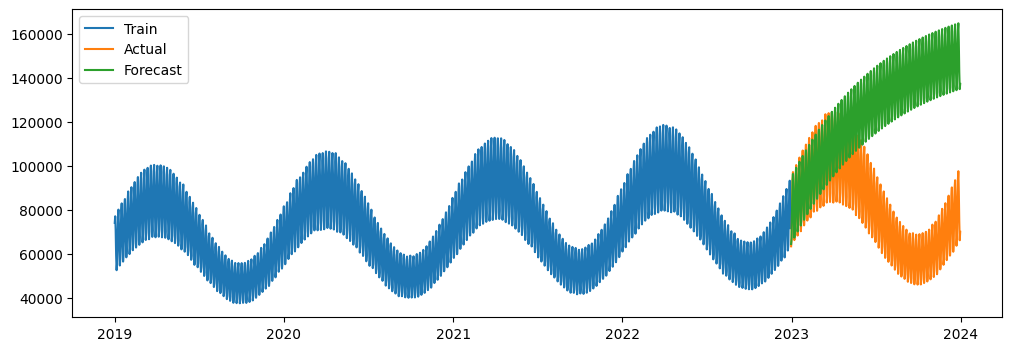

2024-01-01     83374.655916
2024-01-02     96433.222835
2024-01-03    100226.641139
2024-01-04     91049.955777
2024-01-05     77539.947446
2024-01-06     68871.934470
2024-01-07     72978.402666
2024-01-08     86045.302455
2024-01-09     99090.516141
2024-01-10    102870.647978
2024-01-11     93680.742582
2024-01-12     80157.580317
2024-01-13     71476.479176
2024-01-14     75569.924649
2024-01-15     88623.866828
2024-01-16    101656.187692
2024-01-17    105423.491172
2024-01-18     96220.821560
2024-01-19     82684.958900
2024-01-20     73991.220866
2024-01-21     78072.092630
2024-01-22     91113.523969
2024-01-23    104133.396548
2024-01-24    107888.313983
2024-01-25     98673.320257
2024-01-26     85125.195104
2024-01-27     76419.255889
2024-01-28     80487.987478
2024-01-29     93517.339343
2024-01-30    106525.192844
Freq: D, dtype: float64


In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# ---- EDIT THESE ----
FILE = "retail_sales.csv"
DATE_COL = "date"
SALES_COL = "sales"
# --------------------

# 1. Load
df = pd.read_csv(r"C:\Users\NAVYA\Downloads\TNSProject\archive (1).zip")
print(df.columns.tolist())
print(df.head())
print(df.info())
print(df.isnull().sum())
# 2. Clean
df[DATE_COL] = pd.to_datetime(df[DATE_COL])
df = df.dropna(subset=[DATE_COL, SALES_COL])

# 3. Total sales per day (handles multiple stores/products)
ts = df.groupby(DATE_COL)[SALES_COL].sum().sort_index()
ts = ts.asfreq("D").fillna(0)  # use "W" or "M" if data is weekly/monthly

ts.plot(figsize=(12, 4), title="Sales over time")
plt.show()

# 4. Train/test split (last 20% for testing)
split = int(len(ts) * 0.8)
train, test = ts[:split], ts[split:]

# 5. Baseline: repeat the last value
naive = np.repeat(train.iloc[-1], len(test))

# 6. Model: Holt-Winters (weekly seasonality)
model = ExponentialSmoothing(
    train, trend="add", damped_trend=True,
    seasonal="add", seasonal_periods=7
).fit()
pred = model.forecast(len(test))

# 7. Evaluate
def report(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    print(f"{name}: MAE={mae:.2f}, RMSE={rmse:.2f}")

report("Naive", test, naive)
report("Holt-Winters", test, pred)

# 8. Plot results
plt.figure(figsize=(12, 4))
plt.plot(train.index, train, label="Train")
plt.plot(test.index, test, label="Actual")
plt.plot(test.index, pred, label="Forecast")
plt.legend()
plt.show()

# 9. Forecast the next 30 days using all data
final = ExponentialSmoothing(
    ts, trend="add", damped_trend=True,seasonal="add", seasonal_periods=7
).fit()
print(final.forecast(30))

Naive: MAE=27611.83, RMSE=31492.10
Random Forest: MAE=505.62, RMSE=820.19
XGBoost: MAE=438.30, RMSE=714.74


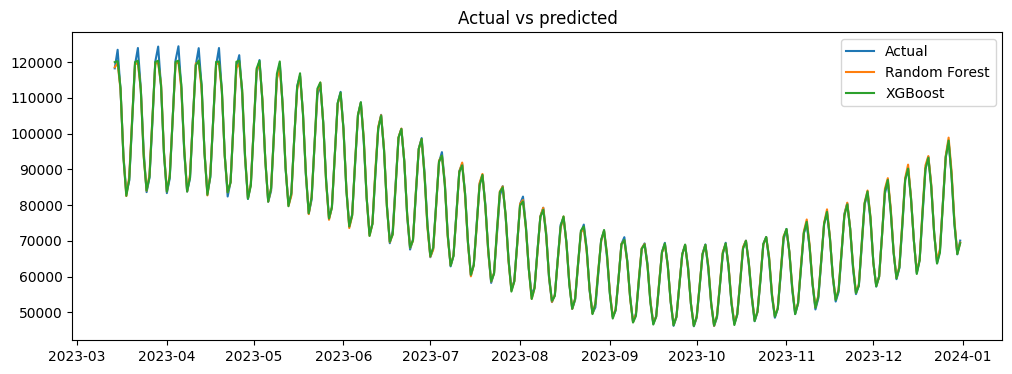

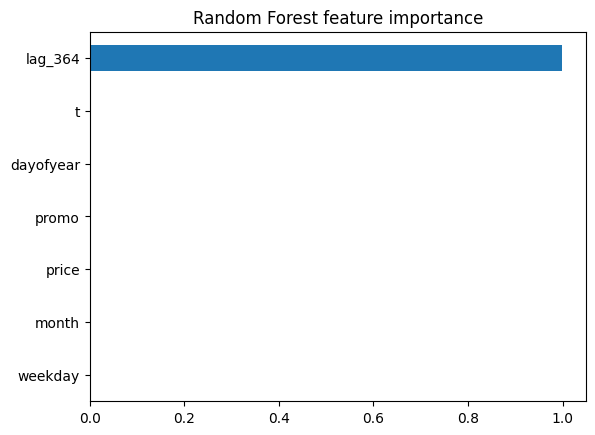

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

# 1. Daily totals (promo = share of rows on promo, price = average price)
daily = df.groupby("date").agg(
    sales=("sales", "sum"),
    price=("price", "mean"),
    promo=("promo", "mean"),
).sort_index().asfreq("D")

# 2. Features
data = daily.copy()
data["weekday"] = data.index.dayofweek
data["month"] = data.index.month
data["dayofyear"] = data.index.dayofyear
data["t"] = np.arange(len(data))            # time index (captures trend)
data["lag_364"] = data["sales"].shift(364)  # same weekday, last year
data = data.dropna()

FEATURES = ["t", "weekday", "month", "dayofyear", "promo", "price", "lag_364"]

# 3. Time-based split (last 20% = test)
split = int(len(data) * 0.8)
X_train, X_test = data[FEATURES][:split], data[FEATURES][split:]
y_train, y_test = data["sales"][:split], data["sales"][split:]

# 4. Models
rf = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

xgb = XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=5, random_state=42)
xgb.fit(X_train, y_train)
xgb_pred = xgb.predict(X_test)

# 5. Compare (naive recomputed on this same test period)
naive_pred = np.repeat(y_train.iloc[-1], len(y_test))

def report(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    print(f"{name}: MAE={mae:.2f}, RMSE={rmse:.2f}")

report("Naive", y_test, naive_pred)
report("Random Forest", y_test, rf_pred)
report("XGBoost", y_test, xgb_pred)

# 6. Plot
plt.figure(figsize=(12, 4))
plt.plot(y_test.index, y_test, label="Actual")
plt.plot(y_test.index, rf_pred, label="Random Forest")
plt.plot(y_test.index, xgb_pred, label="XGBoost")
plt.legend()
plt.title("Actual vs predicted")
plt.show()

# 7. Which features matter most
pd.Series(rf.feature_importances_, index=FEATURES).sort_values().plot(
    kind="barh", title="Random Forest feature importance"
)
plt.savefig("actual_vs_pred.png", dpi=150)
plt.show()